# IT2011 – Company Bankruptcy Prediction

**Group ID:** 2026-Y2-S1-MET-16

**Student Name:** Sandeepana A. G. P.

**IT Number:** IT25102100

**Machine Learning Model:** XGBoost

### Overview

This notebook trains and evaluates an XGBoost classifier on the preprocessed Company Bankruptcy Prediction data (4,958 training and 1,240 test companies, 63 features). It compares a default model, a model weighted with `scale_pos_weight` and a model tuned with `GridSearchCV` (scored by PR-AUC), and adds stratified 5-fold cross-validation, ROC/PR curves, threshold analysis, feature importance and a comparison of SMOTE and under-sampling.

### Model Description

XGBoost builds decision trees sequentially, each tree correcting the errors of the previous ones. The main hyperparameters used are `n_estimators`, `learning_rate` and `max_depth`, and `scale_pos_weight` is used for class imbalance. Tree models do not require scaled inputs.

In [1]:
# Import the libraries
import sys
import warnings
warnings.filterwarnings('ignore')
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, precision_recall_curve
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
SEED = 42
np.random.seed(SEED)
sns.set(color_codes=True)
pd.set_option('display.max_columns', None)

## Data Loading

Reads `train_set.csv` and `test_set.csv` produced by the group preprocessing pipeline and checks their size, missing values, duplicates and class balance. In Colab the cell opens a file-upload dialog; locally, both files must be in the notebook folder.

In [2]:
# Load the dataset (choose train_set.csv and test_set.csv)
import sys
if 'google.colab' in sys.modules:
    from google.colab import files
    files.upload()

train = pd.read_csv('train_set.csv')
test = pd.read_csv('test_set.csv')
print('Train (rows, cols):', train.shape, '| Test:', test.shape)
display(train.head())

Train (rows, cols): (4958, 64) | Test: (1240, 64)


,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Research and development expense rate,Cash flow rate,Interest-bearing debt interest rate,Tax rate (A),Net Value Per Share (B),Net Value Per Share (A),Net Value Per Share (C),Persistent EPS in the Last Four Seasons,Cash Flow Per Share,Operating Profit Per Share (Yuan ¥),Per Share Net profit before tax (Yuan ¥),After-tax Net Profit Growth Rate,Regular Net Profit Growth Rate,Total Asset Growth Rate,Net Value Growth Rate,Cash Reinvestment %,Quick Ratio,Debt ratio %,Net worth/Assets,Borrowing dependency,Contingent liabilities/Net worth,Operating profit/Paid-in capital,Net profit before tax/Paid-in capital,Inventory and accounts receivable/Net value,Total Asset Turnover,Fixed Assets Turnover Frequency,Net Worth Turnover Rate (times),Revenue per person,Operating profit per person,Working Capital to Total Assets,Quick Assets/Total Assets,Current Assets/Total Assets,Cash/Total Assets,Cash/Current Liability,Current Liability to Assets,Operating Funds to Liability,Working Capital/Equity,Current Liabilities/Equity,Retained Earnings to Total Assets,Total expense/Assets,Quick Asset Turnover Rate,Cash Turnover Rate,Fixed Assets to Assets,Current Liability to Equity,Equity to Long-term Liability,Cash Flow to Total Assets,Cash Flow to Liability,CFO to Assets,Cash Flow to Equity,Current Liability to Current Assets,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Equity to Liability,Profitability Ratio,Bankrupt?
0,0.902730,0.961877,0.931724,0.599079,0.599079,0.433868,0.463817,3.707441e-13,0.033404,0.385333,0.392205,0.392205,0.584226,0.716279,0.361210,0.500744,0.785788,0.785788,1.483766e-15,5.836330e-14,0.365624,1.005850e-12,0.260487,0.739513,0.370940,0.005366,0.360129,0.551682,0.572698,0.347826,1.533290e-12,0.131790,1.277402e-11,0.410472,0.707719,0.622912,0.767487,0.299514,1.336367e-12,0.358556,0.329266,0.896420,0.332216,0.847054,0.033793,8.430000e-01,1.155602e-14,1.290577e-12,0.332216,0.124054,0.698013,0.524432,0.483020,0.577867,0.027286,0.0,0.953148,8.871009e-13,0.599079,0.844606,0.280482,0.023064,0.938412,0
1,0.900211,0.929700,0.916617,0.607388,0.607273,0.636273,0.463770,1.237497e-12,0.120154,0.508557,0.514051,0.514051,0.562804,0.711085,0.428065,0.509172,0.785154,0.785154,1.384687e-15,9.281800e-14,0.360853,1.523171e-12,0.137292,0.862708,0.370148,0.005366,0.427950,0.542687,0.567297,0.221889,6.451813e-14,0.074896,4.030268e-12,0.407273,0.723230,0.585645,0.640588,0.052721,3.833038e-13,0.219507,0.329980,0.894227,0.328812,0.832391,0.045536,1.290906e-14,3.190000e-01,2.046087e-11,0.328812,0.120301,0.629899,0.515394,0.468411,0.557191,0.019938,0.0,0.928694,1.254895e-12,0.607383,0.842607,0.276923,0.049663,0.968177,0
2,0.738258,0.831541,0.759727,0.598178,0.598178,0.000000,0.459051,6.859272e-13,0.000000,0.254642,0.262974,0.262974,0.409348,0.662093,0.277817,0.382251,0.786261,0.786261,6.456456e-01,4.972154e-14,0.338767,3.966760e-13,0.426262,0.573738,0.396026,0.005366,0.277757,0.422619,0.591984,0.148426,2.067306e-14,0.134041,2.698849e-12,0.392065,0.434580,0.468679,0.543474,0.005126,1.347105e-14,0.609695,0.316399,0.879566,0.348551,0.749728,0.052304,1.254036e-14,3.760000e-02,4.329394e-11,0.348551,0.120301,0.608940,0.507675,0.386698,0.553959,0.065632,0.0,0.849677,9.252321e-14,0.598178,0.841080,0.295111,0.011068,0.887712,0
3,0.845523,0.882861,0.872057,0.601270,0.601191,0.522044,0.459198,9.364573e-13,0.078854,0.340110,0.347487,0.347487,0.488218,0.685116,0.351760,0.418774,0.785386,0.785386,8.158158e-01,6.496966e-14,0.353921,5.690939e-13,0.183152,0.816848,0.372518,0.005366,0.350846,0.457056,0.573164,0.352324,8.216217e-14,0.128576,5.059258e-12,0.400669,0.693314,0.308338,0.668864,0.054874,2.981266e-13,0.294215,0.316218,0.893972,0.330132,0.801849,0.072275,3.150000e-01,1.850

Total null values  - train: 0 | test: 0
Duplicate rows     - train: 0 | test: 0


,count,mean,std,min,25%,50%,75%,max
ROA(C) before interest and depreciation before interest,4958.0,0.801571,0.075317,0.0,7.587356e-01,7.981472e-01,8.462335e-01,1.000000
ROA(A) before interest and % after tax,4958.0,0.836662,0.070603,0.0,8.047613e-01,8.369583e-01,8.757535e-01,1.000000
ROA(B) before interest and depreciation after tax,4958.0,0.820777,0.070929,0.0,7.836948e-01,8.181281e-01,8.621825e-01,1.000000
Operating Gross Margin,4958.0,0.607624,0.015897,0.0,6.005005e-01,6.056660e-01,6.130457e-01,0.665151
Realized Sales Gross Margin,4958.0,0.607602,0.015875,0.0,6.004987e-01,6.056372e-01,6.130079e-01,0.665151
Research and development expense rate,4958.0,0.195002,0.256110,0.0,1.226606e-14,5.951904e-02,3.406814e-01,1.000000
Cash flow rate,4958.0,0.467467,0.017142,0.0,4.616613e-01,4.651049e-01,4.705745e-01,1.000000
Interest-bearing debt interest rate,4958.0,0.016183,0.108018,0.0,2.161832e-13,3.303361e-13,5.546009e-13,1.000000


Train:  {0: 4782, 1: 176} -> bankrupt = 3.55%


Test:  {0: 1196, 1: 44} -> bankrupt = 3.55%


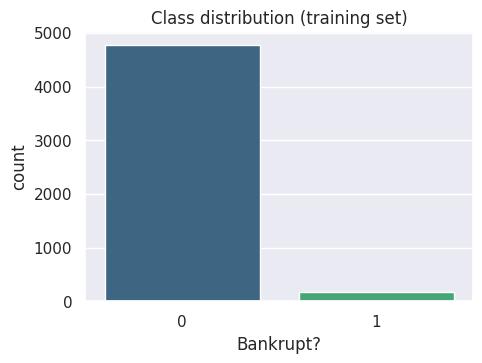

In [3]:
# Check missing values and duplicates
target_col = 'Bankrupt?'
print('Total null values  - train:', train.isnull().sum().sum(), '| test:', test.isnull().sum().sum())
print('Duplicate rows     - train:', train.duplicated().sum(), '| test:', test.duplicated().sum())
display(train.drop(columns=[target_col]).describe().T.head(8))

for name, d in [('Train', train), ('Test', test)]:
    cc = d[target_col].value_counts().sort_index()
    print(f'{name}: ', {int(k): int(v) for k, v in cc.items()}, f'-> bankrupt = {d[target_col].mean() * 100:.2f}%')
plt.figure(figsize=(5, 3.5))
sns.countplot(x=train[target_col], palette='viridis')
plt.title('Class distribution (training set)')
plt.show()

### Class Distribution

About 3.5% of companies are bankrupt in both sets (176 of 4,958 in training, 44 of 1,240 in test; roughly 27 non-bankrupt companies per bankrupt one). Accuracy is therefore misleading, so models are judged by precision, recall, F1, ROC-AUC and PR-AUC for the bankrupt class.

## Data Preparation

Separates the 63 features (`X`) from the target `Bankrupt?` (`y`) in both sets. The group pipeline has already handled missing values and duplicates, removed outliers, scaled the features with MinMax scaling and created a stratified 80/20 train/test split.

In [4]:
# Split the inputs (X) and the answer (y)
X_train, y_train = (train.drop(columns=[target_col]), train[target_col].astype(int))
X_test, y_test = (test.drop(columns=[target_col]), test[target_col].astype(int))
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('Feature range  min =', round(X_train.min().min(), 4), '| max =', round(X_train.max().max(), 4), '(MinMax scaled)')
neg, pos = ((y_train == 0).sum(), (y_train == 1).sum())
spw = neg / pos
print(f'Train negatives = {neg}, positives = {pos}, ratio = {spw:.1f}')

X_train: (4958, 63) | X_test: (1240, 63)
Feature range  min = 0.0 | max = 5.1245 (MinMax scaled)
Train negatives = 4782, positives = 176, ratio = 27.2


## Optional Sample Data

Loads an optional CSV of companies for demonstration (used in the sample-data prediction section). Raw-valued files are rescaled with the pipeline's min/max values in the next cell; set `SAMPLE_IS_SCALED = True` if the file is already scaled.

In [5]:
#@title Scaling values from our group pipeline (do not change)
SCALER_PARAMS = {"ROA(C) before interest and depreciation before interest": [0.0242772875737337, 0.624189538341539], "ROA(A) before interest and % after tax": [0.0, 0.669210641081552], "ROA(B) before interest and depreciation after tax": [0.0335135713903313, 0.667862305262594], "Operating Gross Margin": [0.0, 1.0], "Realized Sales Gross Margin": [0.0, 1.0], "Research and development expense rate": [0.0, 9980000000.0], "Cash flow rate": [0.0, 1.0], "Interest-bearing debt interest rate": [0.0, 990000000.0], "Tax rate (A)": [0.0, 1.0], "Net Value Per Share (B)": [0.0696557245796637, 0.475917576166196], "Net Value Per Share (A)": [0.065062576376891, 0.475917576166196], "Net Value Per Share (C)": [0.065062576376891, 0.475917576166196], "Persistent EPS in the Last Four Seasons": [0.0, 0.485487378273613], "Cash Flow Per Share": [0.0, 0.456249557897715], "Operating Profit Per Share (Yuan ¥)": [0.0, 0.344678772086964], "Per Share Net profit before tax (Yuan ¥)": [0.0, 0.455750546057091], "After-tax Net Profit Growth Rate": [0.0, 0.878199450670319], "Regular Net Profit Growth Rate": [0.0, 0.878199450670319], "Total Asset Growth Rate": [0.0001000017430093, 9990000000.0], "Net Value Growth Rate": [0.0, 9330000000.0], "Cash Reinvestment %": [0.0258280242911963, 1.0], "Quick Ratio": [0.0, 9230000000.0], "Debt ratio %": [0.0, 0.525410406022311], "Net worth/Assets": [0.474589593977688, 1.0], "Borrowing dependency": [0.0, 1.0], "Contingent liabilities/Net worth": [0.0, 1.0], "Operating profit/Paid-in capital": [0.0, 0.344683830833618], "Net profit before tax/Paid-in capital": [0.0, 0.409931377724154], "Inventory and accounts receivable/Net value": [0.0, 0.707444706285846], "Total Asset Turnover": [0.0, 1.0], "Fixed Assets Turnover Frequency": [0.0, 9990000000.0], "Net Worth Turnover Rate (times)": [0.0088709677419354, 0.510645161290323], "Revenue per person": [0.0, 8810000000.0], "Operating profit per person": [0.0, 1.0], "Working Capital to Total Assets": [0.494209926721939, 1.0], "Quick Assets/Total Assets": [0.0, 1.0], "Current Assets/Total Assets": [0.0, 0.998799978746396], "Cash/Total Assets": [0.0, 1.0], "Cash/Current Liability": [0.0, 9650000000.0], "Current Liability to Assets": [0.0, 0.343142736694419], "Operating Funds to Liability": [0.0262740530560835, 1.0], "Working Capital/Equity": [0.0, 0.825196505065642], "Current Liabilities/Equity": [0.0, 1.0], "Retained Earnings to Total Assets": [0.729195620039959, 0.992404080456352], "Total expense/Assets": [0.0, 0.463482794907766], "Quick Asset Turnover Rate": [0.0, 10000000000.0], "Cash Turnover Rate": [0.0, 10000000000.0], "Fixed Assets to Assets": [0.0, 8320000000.0], "Current Liability to Equity": [0.0, 1.0], "Equity to Long-term Liability": [0.0, 0.92212804091503], "Cash Flow to Total Assets": [0.0920885727978348, 1.0], "Cash Flow to Liability": [0.0, 0.905119835412887], "CFO to Assets": [0.227030054355179, 0.983204826211152], "Cash Flow to Equity": [0.0, 0.56923067580019], "Current Liability to Current Assets": [0.0, 0.916814252922595], "Liability-Assets Flag": [0.0, 1.0], "Net Income to Total Assets": [0.411809224581685, 0.870425190877247], "Total assets to GNP price": [0.0001015558155665, 9650000000.0], "Gross Profit to Sales": [0.0, 1.0], "Net Income to Stockholder's Equity": [0.0, 1.0], "Liability to Equity": [0.0, 1.0], "Equity to Liability": [0.0039462801534101, 1.0]}

In [6]:
# Load your own sample data (optional)
SAMPLE_IS_SCALED = False

if 'google.colab' in sys.modules:
    from google.colab import files
    uploaded = files.upload()
    sample_file = list(uploaded.keys())[0] if uploaded else None
else:
    sample_file = 'sample_data_example.csv'

sample_X, sample_y = None, None
if sample_file:
    sample = pd.read_csv(sample_file)
    sample.columns = sample.columns.str.strip()
    if 'Bankrupt?' in sample.columns:
        sample_y = sample['Bankrupt?'].astype(int).values

    if SAMPLE_IS_SCALED:
        sample_X = sample[list(X_train.columns)]
    else:
        sample_X = pd.DataFrame()
        for name, (low, high) in SCALER_PARAMS.items():
            sample_X[name] = (sample[name] - low) / (high - low)
        sample_X['Profitability Ratio'] = (sample_X['ROA(C) before interest and depreciation before interest']
                                           / (sample_X['ROA(A) before interest and % after tax'] + 0.0001))
        sample_X = sample_X[list(X_train.columns)]
    print('Sample data loaded:', len(sample_X), 'companies')
else:
    print('No sample data chosen')

Sample data loaded: 6 companies


### Limitation: Scaler Fitted Before the Split

The group pipeline fitted the scaler on the full dataset before splitting, so test data slightly influenced the scaling. All tuning below uses the training set only; the test set is used for final scores.

## Evaluation Helper

`evaluate_model()` evaluates a fitted model on the test set (classification report, confusion matrix, accuracy, precision, recall, F1, ROC-AUC, PR-AUC) and also records the train F1. Since a missed bankruptcy is usually costlier than a false alarm, recall is monitored closely.

In [7]:
# Function to test any model
results = []


def evaluate_model(name, model, show=True):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    row = {'Model': name, 'Accuracy': accuracy_score(y_test, y_pred), 'Precision': precision_score(y_test, y_pred, zero_division=0), 'Recall': recall_score(y_test, y_pred), 'F1': f1_score(y_test, y_pred), 'ROC-AUC': roc_auc_score(y_test, y_prob), 'PR-AUC': average_precision_score(y_test, y_prob), 'Train F1': f1_score(y_train, model.predict(X_train))}
    results.append(row)
    if show:
        print(classification_report(y_test, y_pred, target_names=['Not bankrupt', 'Bankrupt'], digits=3, zero_division=0))
        cm = confusion_matrix(y_test, y_pred)
        ConfusionMatrixDisplay(cm, display_labels=['Not bankrupt', 'Bankrupt']).plot(cmap='Blues', values_format='d')
        plt.title(f'Confusion matrix - {name} (test set)')
        plt.show()
        tn, fp, fn, tp = cm.ravel()
        print(f'Caught {tp} of {tp + fn} bankrupt companies | {fp} false alarms | ROC-AUC = {row['ROC-AUC']:.3f} | PR-AUC = {row['PR-AUC']:.3f}')
    return row

## Baseline Model

`XGBClassifier` with 200 trees, learning rate 0.1, maximum depth 4 and no imbalance handling.

Fit time 1.1s
              precision    recall  f1-score   support

Not bankrupt      0.984     1.000     0.992      1196
    Bankrupt      1.000     0.545     0.706        44

    accuracy                          0.984      1240
   macro avg      0.992     0.773     0.849      1240
weighted avg      0.984     0.984     0.982      1240



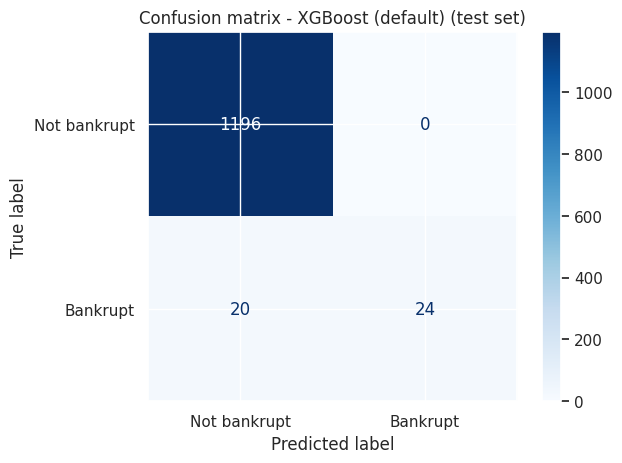

Caught 24 of 44 bankrupt companies | 0 false alarms | ROC-AUC = 0.964 | PR-AUC = 0.785


{'Model': 'XGBoost (default)',
 'Accuracy': 0.9838709677419355,
 'Precision': 1.0,
 'Recall': 0.5454545454545454,
 'F1': 0.7058823529411765,
 'ROC-AUC': 0.963704773487382,
 'PR-AUC': 0.784954141781546,
 'Train F1': 1.0}

In [8]:
# Train the default model
t = time.time()
base_model = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, eval_metric='logloss', random_state=SEED, n_jobs=-1)
base_model.fit(X_train, y_train)
print(f'Fit time {time.time() - t:.1f}s')
evaluate_model('XGBoost (default)', base_model)

## Class Imbalance Handling

The same configuration with `scale_pos_weight` = 4,782 / 176 ≈ 27.2, so each bankrupt company carries about 27 times the weight of a non-bankrupt one during training.

              precision    recall  f1-score   support

Not bankrupt      0.988     0.995     0.991      1196
    Bankrupt      0.829     0.659     0.734        44

    accuracy                          0.983      1240
   macro avg      0.908     0.827     0.863      1240
weighted avg      0.982     0.983     0.982      1240



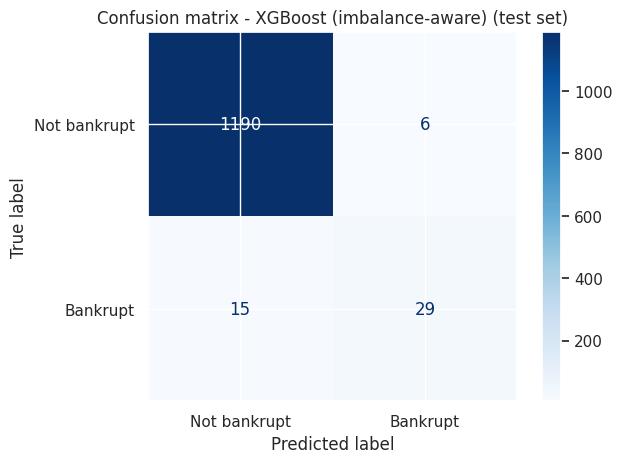

Caught 29 of 44 bankrupt companies | 6 false alarms | ROC-AUC = 0.956 | PR-AUC = 0.752


{'Model': 'XGBoost (imbalance-aware)',
 'Accuracy': 0.9830645161290322,
 'Precision': 0.8285714285714286,
 'Recall': 0.6590909090909091,
 'F1': 0.7341772151898734,
 'ROC-AUC': 0.9559136515658255,
 'PR-AUC': 0.7523144992054681,
 'Train F1': 0.9971671388101983}

In [9]:
# Train the imbalance-aware model
bal_model = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, scale_pos_weight=spw, eval_metric='logloss', random_state=SEED, n_jobs=-1)
bal_model.fit(X_train, y_train)
evaluate_model('XGBoost (imbalance-aware)', bal_model)

### Default vs Imbalance-Aware Results

The default model catches 24 of 44 bankrupt companies with no false alarms (recall 0.545). With `scale_pos_weight` it catches 29 with 6 false alarms (recall 0.659, precision 0.829). The weighting mainly shifts the balance between recall and precision; ROC-AUC does not improve (0.964 → 0.956).

## Overfitting Check

Compares train F1 with test F1 for each model version. A large gap indicates overfitting; low and similar scores indicate underfitting.

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Train F1
Model,,,,,,,
XGBoost (default),0.984,1.000,0.545,0.706,0.964,0.785,1.000
XGBoost (imbalance-aware),0.983,0.829,0.659,0.734,0.956,0.752,0.997


,Train F1,Test F1,Gap
Model,,,
XGBoost (default),1.000,0.706,0.294
XGBoost (imbalance-aware),0.997,0.734,0.263


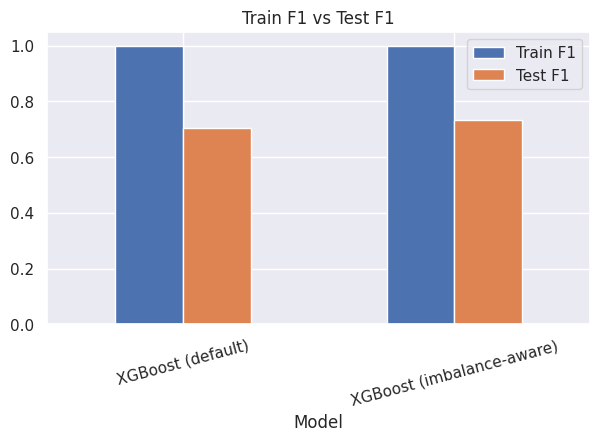

In [10]:
# Compare train score and test score (overfitting check)
res = pd.DataFrame(results).set_index('Model')
display(res.round(3))
gap = res[['Train F1', 'F1']].rename(columns={'F1': 'Test F1'})
gap['Gap'] = gap['Train F1'] - gap['Test F1']
display(gap.round(3))
gap[['Train F1', 'Test F1']].plot(kind='bar', figsize=(7, 3.8), title='Train F1 vs Test F1')
plt.xticks(rotation=15)
plt.show()

## Cross-Validation

Stratified 5-fold cross-validation (seed 42) on the training set using the weighted XGBoost configuration. Each fold keeps the class ratio, and the mean and standard deviation of each metric show how stable the model is without using the test set.

,recall,precision,f1,roc_auc,pr_auc
fold,,,,,
1,0.686,0.706,0.696,0.967,0.783
2,0.629,0.688,0.657,0.931,0.701
3,0.639,0.622,0.630,0.909,0.677
4,0.514,0.783,0.621,0.940,0.649
5,0.486,0.567,0.523,0.944,0.606


Mean +/- std per metric:


,mean,std
recall,0.591,0.086
precision,0.673,0.083
f1,0.625,0.064
roc_auc,0.938,0.021
pr_auc,0.683,0.066


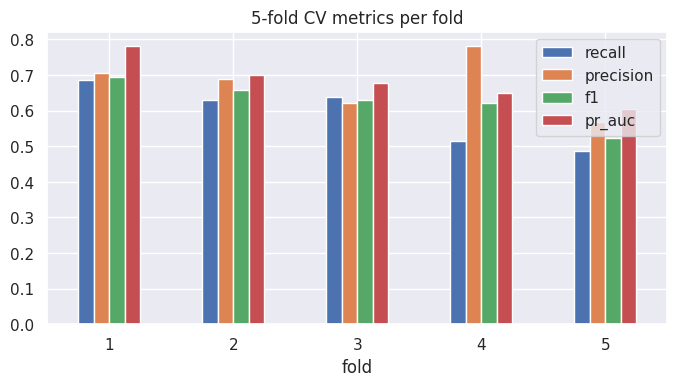

In [11]:
# 5-fold cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_est = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, scale_pos_weight=spw, eval_metric='logloss', random_state=SEED, n_jobs=-1)
rows = []

for fold, (tr, va) in enumerate(skf.split(X_train, y_train), start=1):
    m = clone(cv_est).fit(X_train.iloc[tr], y_train.iloc[tr])
    yb = y_train.iloc[va]
    p, pr = (m.predict(X_train.iloc[va]), m.predict_proba(X_train.iloc[va])[:, 1])
    rows.append({'fold': fold, 'recall': recall_score(yb, p), 'precision': precision_score(yb, p, zero_division=0), 'f1': f1_score(yb, p), 'roc_auc': roc_auc_score(yb, pr), 'pr_auc': average_precision_score(yb, pr)})
cv_df = pd.DataFrame(rows).set_index('fold')
display(cv_df.round(3))
print('Mean +/- std per metric:')
display(pd.DataFrame({'mean': cv_df.mean(), 'std': cv_df.std()}).round(3))
cv_df[['recall', 'precision', 'f1', 'pr_auc']].plot(kind='bar', figsize=(8, 3.8), title='5-fold CV metrics per fold')
plt.xticks(rotation=0)
plt.show()

## Hyperparameter Tuning

`GridSearchCV` with stratified 3-fold cross-validation on the training set, optimising PR-AUC (average precision), which does not depend on the 0.5 threshold and focuses on the rare bankrupt class.

Search space: `n_estimators` ∈ {100, 300}, `max_depth` ∈ {2, 4, 6}, `learning_rate` ∈ {0.03, 0.1} (12 combinations, 3-fold CV), with `scale_pos_weight` fixed.

Best parameters: 300 trees, depth 2, learning rate 0.03 (CV PR-AUC 0.663). The search preferred shallow trees with small steps.

In [12]:
# Tune the settings with GridSearchCV
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
param_grid = {'n_estimators': [100, 300], 'max_depth': [2, 4, 6], 'learning_rate': [0.03, 0.1]}
t = time.time()
gs = GridSearchCV(XGBClassifier(scale_pos_weight=spw, eval_metric='logloss', random_state=SEED, n_jobs=-1), param_grid, scoring='average_precision', cv=cv3, n_jobs=-1)
gs.fit(X_train, y_train)
best = gs.best_estimator_
print(f'Grid search took {time.time() - t:.1f}s')
print('Best parameters:', gs.best_params_, '| best CV PR-AUC:', round(gs.best_score_, 3))
cvres = pd.DataFrame(gs.cv_results_)[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].sort_values('rank_test_score')
display(cvres.head(8).round(3))

Grid search took 36.0s
Best parameters: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300} | best CV PR-AUC: 0.663


,params,mean_test_score,std_test_score,rank_test_score
1,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",0.663,0.072,1
6,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.662,0.075,2
11,"{'learning_rate': 0.1, 'max_depth': 6, 'n_esti...",0.657,0.072,3
3,"{'learning_rate': 0.03, 'max_depth': 4, 'n_est...",0.655,0.057,4
5,"{'learning_rate': 0.03, 'max_depth': 6, 'n_est...",0.655,0.069,5
10,"{'learning_rate': 0.1, 'max_depth': 6, 'n_esti...",0.653,0.075,6
9,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti...",0.653,0.058,7
8,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti...",0.651,0.057,8


              precision    recall  f1-score   support

Not bankrupt      0.994     0.929     0.960      1196
    Bankrupt      0.303     0.841     0.446        44

    accuracy                          0.926      1240
   macro avg      0.649     0.885     0.703      1240
weighted avg      0.969     0.926     0.942      1240



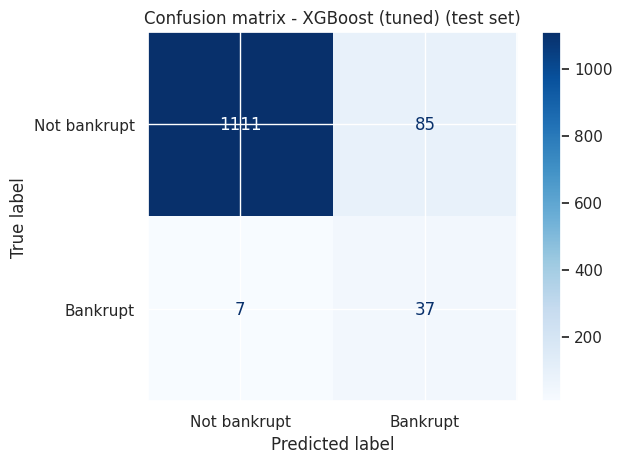

Caught 37 of 44 bankrupt companies | 85 false alarms | ROC-AUC = 0.968 | PR-AUC = 0.791


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Train F1
Model,,,,,,,
XGBoost (default),0.984,1.000,0.545,0.706,0.964,0.785,1.000
XGBoost (imbalance-aware),0.983,0.829,0.659,0.734,0.956,0.752,0.997
XGBoost (tuned),0.926,0.303,0.841,0.446,0.968,0.791,0.488


In [13]:
# Test the tuned model
evaluate_model('XGBoost (tuned)', best)
res = pd.DataFrame(results).set_index('Model')
display(res.round(3))

## Additional Experiments

### Model-Specific Experiment

Trains the weighted model with 10, 25, 50, 100, 200 and 400 trees (learning rate 0.1, depth 4) and compares train F1, test F1 and test PR-AUC.

,train F1,test F1,test PR-AUC
trees,,,
10,0.470,0.434,0.653
25,0.540,0.480,0.754
50,0.668,0.531,0.750
100,0.893,0.660,0.758
200,0.997,0.734,0.752
400,1.000,0.753,0.759


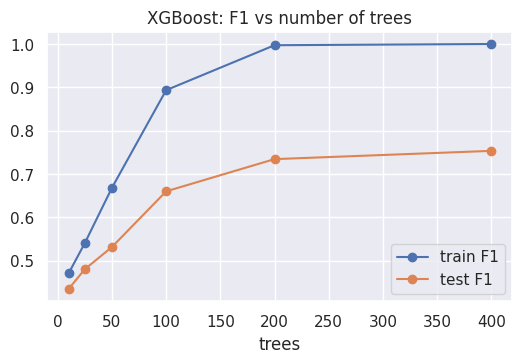

In [14]:
# Experiment: different numbers of trees
rows = []

for n in [10, 25, 50, 100, 200, 400]:
    m = XGBClassifier(n_estimators=n, learning_rate=0.1, max_depth=4, scale_pos_weight=spw, eval_metric='logloss', random_state=SEED, n_jobs=-1).fit(X_train, y_train)
    rows.append({'trees': n, 'train F1': f1_score(y_train, m.predict(X_train)), 'test F1': f1_score(y_test, m.predict(X_test)), 'test PR-AUC': average_precision_score(y_test, m.predict_proba(X_test)[:, 1])})
t_df = pd.DataFrame(rows).set_index('trees')
display(t_df.round(3))
t_df[['train F1', 'test F1']].plot(marker='o', figsize=(6, 3.5), title='XGBoost: F1 vs number of trees')
plt.show()

**Observation.** Train F1 rises from 0.470 (10 trees) to 1.000 (400 trees), i.e. the model fits the training data almost perfectly. Test PR-AUC is about 0.75 from 25 trees onwards (0.754 at 25, 0.759 at 400), while test F1 continues to rise slowly (0.434 → 0.753). More trees therefore add little to ranking quality.

### ROC and Precision–Recall Curves

Curves for the tuned model on the test set, showing performance across all decision thresholds. The dashed line in the precision–recall plot is the random-classifier baseline (the bankrupt prevalence, about 3.5%).

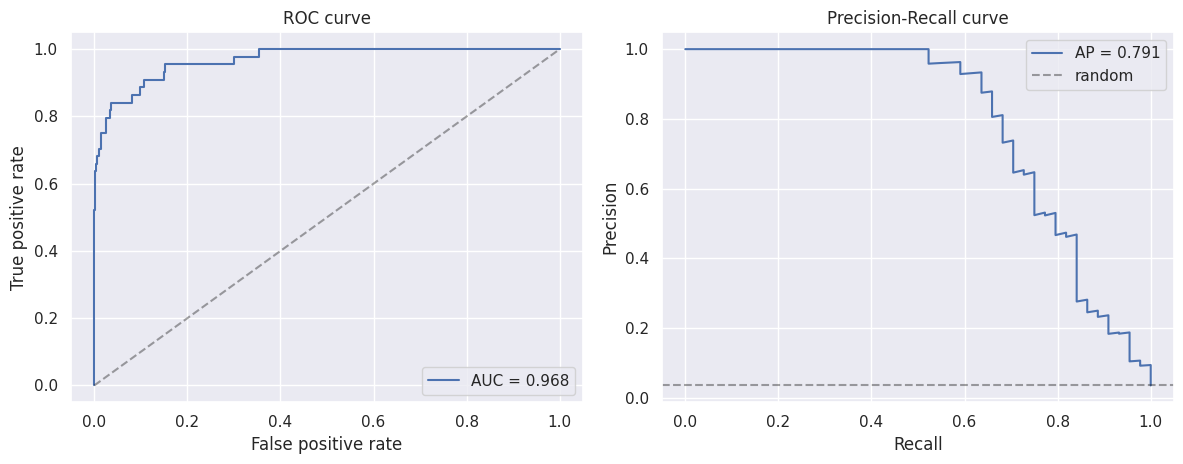

In [15]:
# Draw the ROC and Precision-Recall curves
prob = best.predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
fpr, tpr, _ = roc_curve(y_test, prob)
ax[0].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, prob):.3f}')
ax[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
ax[0].set(title='ROC curve', xlabel='False positive rate', ylabel='True positive rate')
ax[0].legend()
p, r, _ = precision_recall_curve(y_test, prob)
ax[1].plot(r, p, label=f'AP = {average_precision_score(y_test, prob):.3f}')
ax[1].axhline(y_test.mean(), color='k', ls='--', alpha=0.4, label='random')
ax[1].set(title='Precision-Recall curve', xlabel='Recall', ylabel='Precision')
ax[1].legend()
plt.tight_layout()
plt.show()

### Threshold Tuning

Precision, recall and F1 of the tuned model on the test set for decision thresholds from 0.1 to 0.9 (default 0.5).

,precision,recall,F1,flagged
threshold,,,,
0.1,0.110,0.955,0.197,382
0.2,0.167,0.955,0.285,251
0.3,0.204,0.909,0.333,196
0.4,0.242,0.886,0.380,161
0.5,0.303,0.841,0.446,122
0.6,0.394,0.841,0.536,94
0.7,0.522,0.795,0.631,67
0.8,0.738,0.705,0.721,42
0.9,1.000,0.500,0.667,22


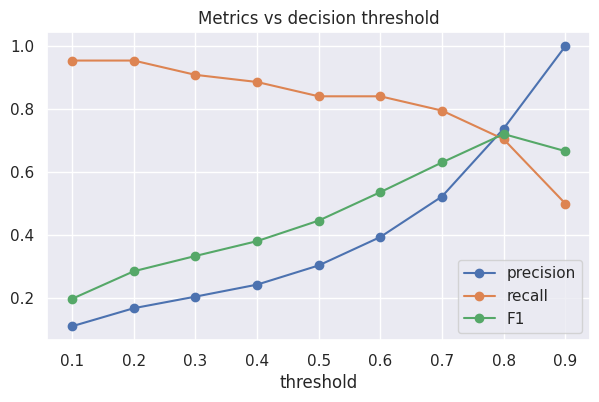

In [16]:
# Try different cut-off values (threshold)
rows = []

for th in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    p = (prob >= th).astype(int)
    rows.append({'threshold': th, 'precision': precision_score(y_test, p, zero_division=0), 'recall': recall_score(y_test, p), 'F1': f1_score(y_test, p), 'flagged': int(p.sum())})
th_df = pd.DataFrame(rows).set_index('threshold')
display(th_df.round(3))
th_df[['precision', 'recall', 'F1']].plot(marker='o', figsize=(7, 4), title='Metrics vs decision threshold')
plt.show()

Raising the threshold from 0.5 to 0.8 increases the tuned model's F1 from 0.446 to 0.721 (precision 0.738, recall 0.705).

Note: the threshold is examined on the test set for illustration only; in practice it should be selected on validation data.

### Feature Importance

The 12 most important features of the tuned model. Importance reflects how much the model uses a feature, not a causal effect.

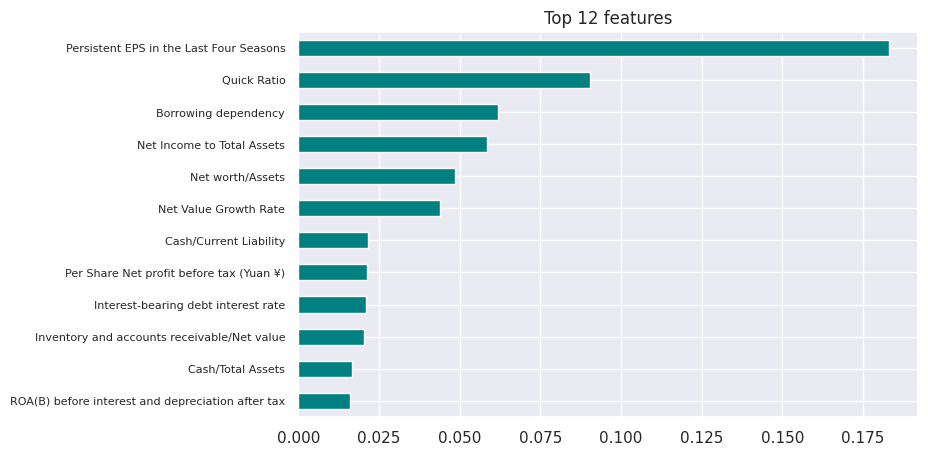

In [17]:
# Show the most important ratios
imp = pd.Series(best.feature_importances_, index=X_train.columns).sort_values().tail(12)
imp.plot(kind='barh', figsize=(8, 5), color='teal', title='Top 12 features')
plt.tick_params(axis='y', labelsize=8)
plt.show()

## Resampling Comparison

Compares four treatments of the training data with default model settings: no change, class weights, SMOTE (synthetic bankrupt samples) and random under-sampling. Resampling is applied only inside the training part of each fold (via an `imblearn` pipeline); validation folds and the test set are never resampled. Reports 5-fold CV and test-set metrics.

,CV Recall,CV Precision,CV PR-AUC,Test Recall,Test Precision,Test F1,Test PR-AUC
Version,,,,,,,
No change (default),0.494,0.854,0.691,0.545,1.000,0.706,0.785
Class weights,0.591,0.673,0.683,0.659,0.829,0.734,0.752
SMOTE,0.653,0.531,0.697,0.636,0.651,0.644,0.689
Under-sampling,0.881,0.191,0.525,0.909,0.223,0.359,0.494


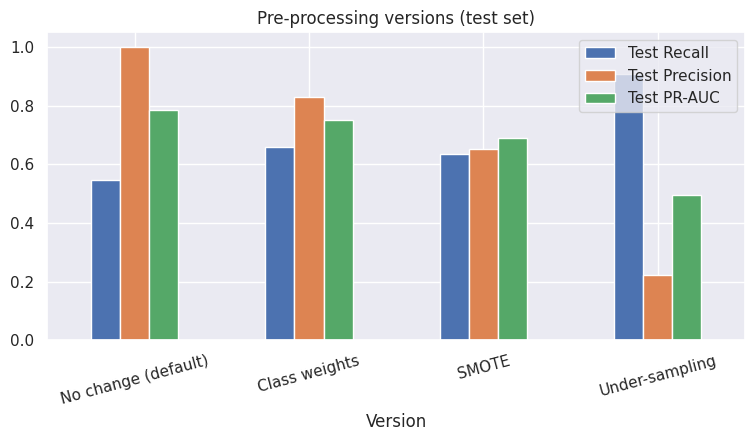

In [18]:
# Compare no change, class weights, SMOTE and under-sampling
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
variants = {'No change (default)': clone(base_model), 'Class weights': clone(bal_model), 'SMOTE': ImbPipeline([('sampler', SMOTE(random_state=SEED)), ('model', clone(base_model))]), 'Under-sampling': ImbPipeline([('sampler', RandomUnderSampler(random_state=SEED)), ('model', clone(base_model))])}


def scores(y_true, pred, prob):
    return {'Recall': recall_score(y_true, pred), 'Precision': precision_score(y_true, pred, zero_division=0), 'F1': f1_score(y_true, pred), 'PR-AUC': average_precision_score(y_true, prob)}
rows = []

for name, est in variants.items():
    folds = []
    for tr, va in skf.split(X_train, y_train):
        m = clone(est).fit(X_train.iloc[tr], y_train.iloc[tr])
        folds.append(scores(y_train.iloc[va], m.predict(X_train.iloc[va]), m.predict_proba(X_train.iloc[va])[:, 1]))
    cv = pd.DataFrame(folds).mean()
    m = clone(est).fit(X_train, y_train)
    te = scores(y_test, m.predict(X_test), m.predict_proba(X_test)[:, 1])
    rows.append({'Version': name, 'CV Recall': cv['Recall'], 'CV Precision': cv['Precision'], 'CV PR-AUC': cv['PR-AUC'], 'Test Recall': te['Recall'], 'Test Precision': te['Precision'], 'Test F1': te['F1'], 'Test PR-AUC': te['PR-AUC']})
prep_df = pd.DataFrame(rows).set_index('Version')
display(prep_df.round(3))
prep_df[['Test Recall', 'Test Precision', 'Test PR-AUC']].plot(kind='bar', figsize=(9, 4), title='Pre-processing versions (test set)')
plt.xticks(rotation=15)
plt.show()

**Observation.** SMOTE gives about the same CV PR-AUC as no change (0.697 vs 0.691) but a lower test PR-AUC (0.689 vs 0.785). Under-sampling is clearly worse (CV PR-AUC 0.525, test PR-AUC 0.494, test precision 0.223). No resampling or class weights are therefore preferable for XGBoost.

## Predicting Individual Companies

`predict_company()` returns the tuned model's bankruptcy probability and predicted label for a company defined by (scaled, 0–1) feature values, starting either from the typical non-bankrupt company or from a real test company. `MY_COMPANY` is empty by default; the cell also shows demonstration cases from the test set, including a what-if where key ratios are set to non-bankrupt values.

In [19]:
# Try your own company
healthy_typical = X_train[y_train == 0].median()
bankrupt_typical = X_train[y_train == 1].median()

# The 8 ratios where bankrupt and healthy companies differ most
difference = (bankrupt_typical - healthy_typical).abs() / X_train.std()
KEY_FEATURES = list(difference.sort_values(ascending=False).head(8).index)
display(pd.DataFrame({'healthy': healthy_typical[KEY_FEATURES], 'bankrupt': bankrupt_typical[KEY_FEATURES]}).round(3))

# Function: predict one company
def predict_company(changes, start_row=None, title='My company'):
    if start_row is None:
        company = healthy_typical.copy()
    else:
        company = X_test.iloc[start_row].copy()
    for name, value in changes.items():
        column = [c for c in X_train.columns if name.lower() in c.lower()][0]
        company[column] = value
    one_row = pd.DataFrame([company.values], columns=X_train.columns)
    probability = best.predict_proba(one_row)[0, 1]
    answer = 'BANKRUPT' if best.predict(one_row)[0] == 1 else 'HEALTHY'
    print(title, ': probability =', round(probability * 100, 1), '% ->', answer)

# YOUR AREA: type values between 0 and 1
MY_COMPANY = {}
START_FROM = None
predict_company(MY_COMPANY, START_FROM)

# Demo with real companies from the test data
predictions = best.predict(X_test)
bankrupt_rows = np.where(y_test.values == 1)[0]
caught = [i for i in bankrupt_rows if predictions[i] == 1]
healthy_row = int(np.where(y_test.values == 0)[0][0])
predict_company({}, healthy_row, 'Real healthy company')
predict_company({}, caught[0], 'Real bankrupt company')
what_if = {name: healthy_typical[name] for name in KEY_FEATURES}
predict_company(what_if, caught[0], 'What-if: key ratios set to healthy values')
print(len(caught), 'of', len(bankrupt_rows), 'real bankrupt companies are caught')

,healthy,bankrupt
Net Income to Total Assets,0.872,0.773
Retained Earnings to Total Assets,0.794,0.701
ROA(A) before interest and % after tax,0.839,0.733
Debt ratio %,0.209,0.356
Net worth/Assets,0.791,0.644
ROA(B) before interest and depreciation after tax,0.820,0.717
ROA(C) before interest and depreciation before interest,0.801,0.695
Current Liability to Assets,0.238,0.429


My company : probability = 2.0 % -> HEALTHY
Real healthy company : probability = 1.2 % -> HEALTHY
Real bankrupt company : probability = 97.3 % -> BANKRUPT
What-if: key ratios set to healthy values : probability = 27.8 % -> HEALTHY
37 of 44 real bankrupt companies are caught


## Sample Data Predictions

Applies the tuned model to the optional sample data loaded earlier and, if the file contains `Bankrupt?`, compares the predictions with the actual labels.

In [20]:
# Test the sample data with the model
if sample_X is None:
    print('No sample data chosen')
else:
    probability = best.predict_proba(sample_X)[:, 1]
    answer = best.predict(sample_X)
    result = pd.DataFrame({'company': range(1, len(sample_X) + 1),
                           'probability of bankruptcy %': (probability * 100).round(1),
                           'model says': np.where(answer == 1, 'BANKRUPT', 'HEALTHY')})
    if sample_y is not None:
        result['real answer'] = np.where(sample_y == 1, 'BANKRUPT', 'HEALTHY')
        result['correct?'] = np.where(answer == sample_y, 'yes', 'NO')
        print('Correct:', (answer == sample_y).sum(), 'of', len(sample_y))
    display(result)

Correct: 4 of 6


,company,probability of bankruptcy %,model says,real answer,correct?
0,1,2.700000,HEALTHY,HEALTHY,yes
1,2,81.099998,BANKRUPT,HEALTHY,NO
2,3,9.300000,HEALTHY,HEALTHY,yes
3,4,38.400002,HEALTHY,BANKRUPT,NO
4,5,91.000000,BANKRUPT,BANKRUPT,yes
5,6,83.300003,BANKRUPT,BANKRUPT,yes


## Results Summary

Test-set results (44 bankrupt, 1,196 non-bankrupt companies):

| Version | Caught (of 44) | False alarms | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|---|
| Default | 24 | 0 | 1.000 | 0.545 | 0.706 | 0.964 | 0.785 |
| Imbalance-aware | 29 | 6 | 0.829 | 0.659 | 0.734 | 0.956 | 0.752 |
| Tuned | 37 | 85 | 0.303 | 0.841 | 0.446 | 0.968 | 0.791 |

**5-fold cross-validation (the weighted XGBoost configuration), mean ± std:** recall 0.591 ± 0.086, precision 0.673 ± 0.083, F1 0.625 ± 0.064, ROC-AUC 0.938 ± 0.021, PR-AUC 0.683 ± 0.066.

**Imbalance handling and tuning.** The default model catches 24 of 44 bankrupt companies with no false alarms; `scale_pos_weight` raises this to 29 (6 false alarms); the tuned model catches 37 (85 false alarms, precision 0.303). The tuned model has the highest test PR-AUC (0.791) and recall of the three versions, but its F1 at the 0.5 threshold (0.446) is lower than the default's (0.706) because tuning optimised PR-AUC rather than F1. At threshold 0.8 its F1 is 0.721.

**Overfitting.** The default model has train F1 1.000 vs test F1 0.706. The tuned model selected shallow trees (depth 2, learning rate 0.03) with train F1 0.488 vs test F1 0.446.

**Limitations**

- The test set contains only 44 bankrupt companies, so one company changes recall by about 2.3 percentage points and small differences between versions are within noise.
- The group pipeline fitted `MinMaxScaler` on the full dataset before the train/test split, so test data slightly influenced the scaling.
- Hyperparameters were selected by cross-validation on the training set only; the threshold table is shown on the test set for illustration only.
- SMOTE and under-sampling were evaluated only with default model settings and were not tuned.
- Results come from the seeded run (`random_state = 42`) and may vary slightly on other machines.